In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

df = pd.read_csv('student-por.csv')
df = df.drop(columns=['school'], axis=1, errors='ignore')
print('Dimensões:', df.shape)
df.head()


Dimensões: (649, 32)


,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,F,18,U,GT3,A,4,4,at_home,teacher,course,...,4,3,4,1,1,3,4,0,11,11
1,F,17,U,GT3,T,1,1,at_home,other,course,...,5,3,3,1,1,3,2,9,11,11
2,F,15,U,LE3,T,1,1,at_home,other,other,...,4,3,2,2,3,3,6,12,13,12
3,F,15,U,GT3,T,4,2,health,services,home,...,3,2,2,1,1,5,0,14,14,14
4,F,16,U,GT3,T,3,3,other,other,home,...,4,3,2,1,2,5,0,11,13,13


---
## Pergunta 1
**A existência de um relacionamento amoroso contribui para a diminuição de horas de estudo?**
---


=== Tempo de estudo por relacionamento amoroso ===
Contagem:
           Sem relacionamento  Com relacionamento
studytime                                        
1                         143                  69
2                         188                 117
3                          52                  45
4                          27                   8

Percentual por grupo:
           Sem relacionamento  Com relacionamento
studytime                                        
1                       34.88               28.87
2                       45.85               48.95
3                       12.68               18.83
4                        6.59                3.35

Qui-quadrado: chi2=8.728, gl=3, p-valor=0.0331

Alto estudo (níveis 3-4): sem=19.27%, com=22.18% (diferença de 2.91 pp)


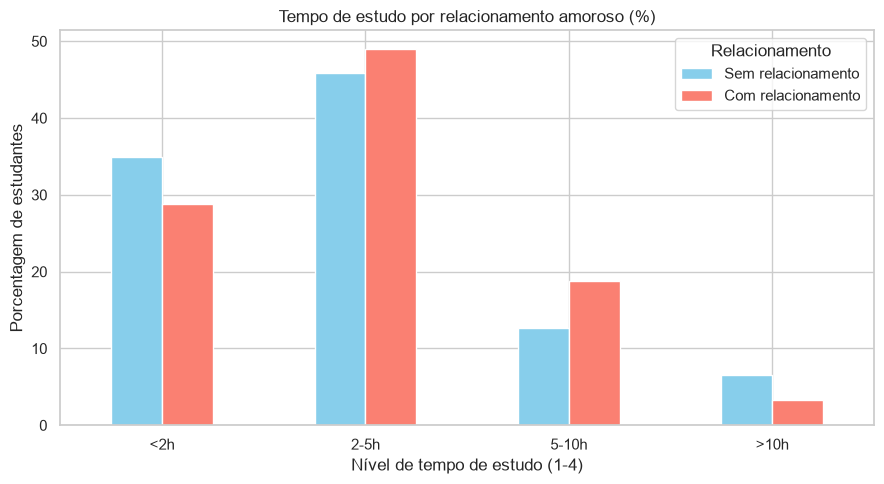

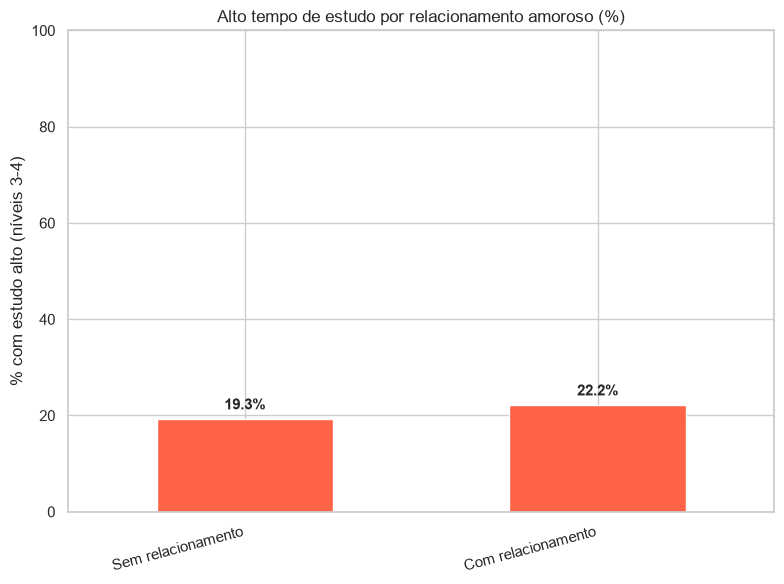

In [ ]:
studytime_labels = {1: '<2h', 2: '2-5h', 3: '5-10h', 4: '>10h'}
df['studytime_label'] = df['studytime'].map(studytime_labels)

print('=== Tempo de estudo por relacionamento amoroso ===')
ct = pd.crosstab(df['studytime'], df['romantic'])[['no','yes']]
ct.columns = ['Sem relacionamento', 'Com relacionamento']
print('Contagem:')
print(ct)
ct_pct = pd.crosstab(df['studytime'], df['romantic'], normalize='columns')*100
ct_pct = ct_pct[['no','yes']]
ct_pct.columns = ['Sem relacionamento', 'Com relacionamento']
print('\nPercentual por grupo:')
print(ct_pct.round(2))
chi2, p, dof, exp = stats.chi2_contingency(pd.crosstab(df['studytime'], df['romantic']))
print(f'\nQui-quadrado: chi2={chi2:.3f}, gl={dof}, p-valor={p:.4f}')

df['high_study'] = df['studytime'] >= 3
rate_no = df.loc[df['romantic']=='no','high_study'].mean()*100
rate_yes = df.loc[df['romantic']=='yes','high_study'].mean()*100
diff = abs(rate_yes - rate_no)
print(f'\nAlto estudo (níveis 3-4): sem={rate_no:.2f}%, com={rate_yes:.2f}% (diferença de {diff:.2f} pp)')

fig, ax = plt.subplots(figsize=(9,5))
ct_pct.plot(kind='bar', ax=ax, color=['skyblue','salmon'])
ax.set_title('Tempo de estudo por relacionamento amoroso (%)')
ax.set_xlabel('Nível de tempo de estudo (1-4)')
ax.set_ylabel('Porcentagem de estudantes')
ax.set_xticklabels([studytime_labels[i] for i in sorted(df['studytime'].unique())], rotation=0)
ax.legend(title='Relacionamento')
plt.tight_layout()
plt.show()

high_tab = pd.DataFrame({'Alto estudo (3-4)': [rate_no, rate_yes]}, index=['Sem relacionamento','Com relacionamento'])
fig, ax = plt.subplots(figsize=(8,6))
high_tab.plot(kind='bar', ax=ax, color=['tomato','steelblue'], legend=False)
ax.set_title('Alto tempo de estudo por relacionamento amoroso (%)')
ax.set_ylabel('% com estudo alto (níveis 3-4)')
ax.set_xticklabels(['Sem relacionamento', 'Com relacionamento'], rotation=15, ha='right')
ax.set_ylim(0, 50)
for i,v in enumerate(high_tab['Alto estudo (3-4)']):
    ax.text(i, v+2, f'{v:.1f}%', ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()


**Relatório - Pergunta 1:**

- **Contagens por nível:** sem relacionamento: 1=143, 2=188, 3=52, 4=27; com relacionamento: 1=69, 2=117, 3=45, 4=8.
- **Percentuais:** sem relacionamento apresenta 12.7% em 5-10h e 6.6% em >10h; com relacionamento apresenta 18.8% em 5-10h e 3.3% em >10h.
- **Qui-quadrado:** p-valor = 0.0331.
- **Alto estudo (níveis 3-4):** sem = 19.27%, com = 22.18% (diferença de 2.91 pp).
- **Conclusão:** não há evidência de que a existência de um relacionamento amoroso contribua para a diminuição das horas de estudo; a distribuição é semelhante, com leve aumento de estudo médio-alto entre quem tem relacionamento.


---
## Pergunta 2
**Estudantes em relacionamentos amorosos apresentam padrões diferentes de consumo de álcool?**
---


=== consumo de álcool durante a semana ===
Contagem:
      Sem relacionamento  Com relacionamento
Dalc                                        
1                    289                 162
2                     75                  46
3                     32                  11
4                      7                  10
5                      7                  10

Percentual por grupo:
      Sem relacionamento  Com relacionamento
Dalc                                        
1                  70.49               67.78
2                  18.29               19.25
3                   7.80                4.60
4                   1.71                4.18
5                   1.71                4.18

Qui-quadrado: chi2=9.642, gl=4, p-valor=0.0469



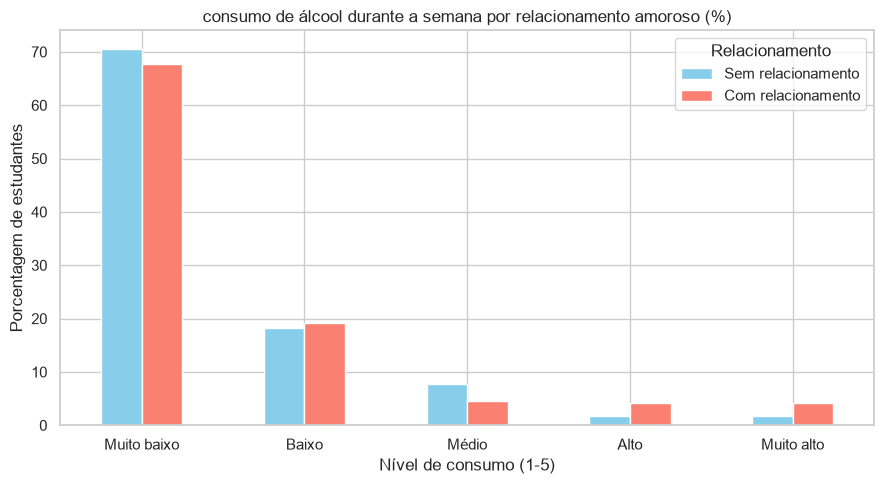

=== consumo de álcool no fim de semana ===
Contagem:
      Sem relacionamento  Com relacionamento
Walc                                        
1                    153                  94
2                     95                  55
3                     75                  45
4                     60                  27
5                     27                  18

Percentual por grupo:
      Sem relacionamento  Com relacionamento
Walc                                        
1                  37.32               39.33
2                  23.17               23.01
3                  18.29               18.83
4                  14.63               11.30
5                   6.59                7.53

Qui-quadrado: chi2=1.635, gl=4, p-valor=0.8025



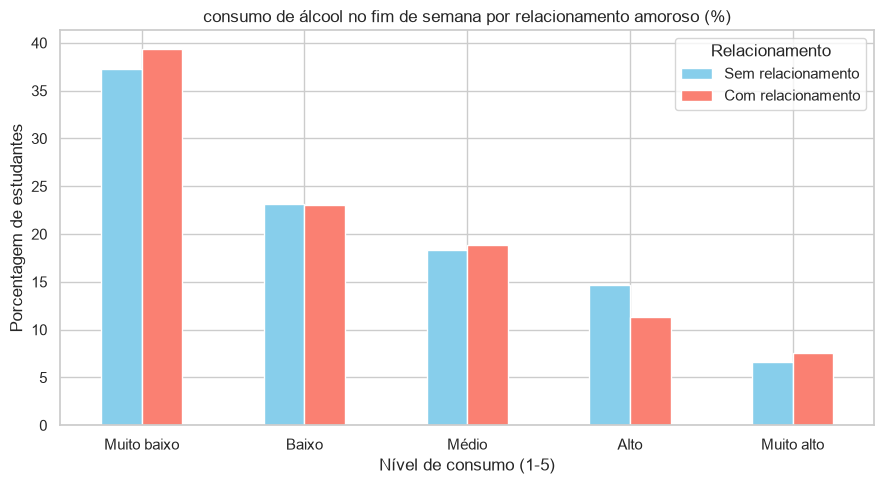

Alto consumo (semana): sem=3.41%, com=8.37% (diferença de 4.95 pp)
Alto consumo (fim de semana): sem=21.22%, com=18.83% (diferença de 2.39 pp)


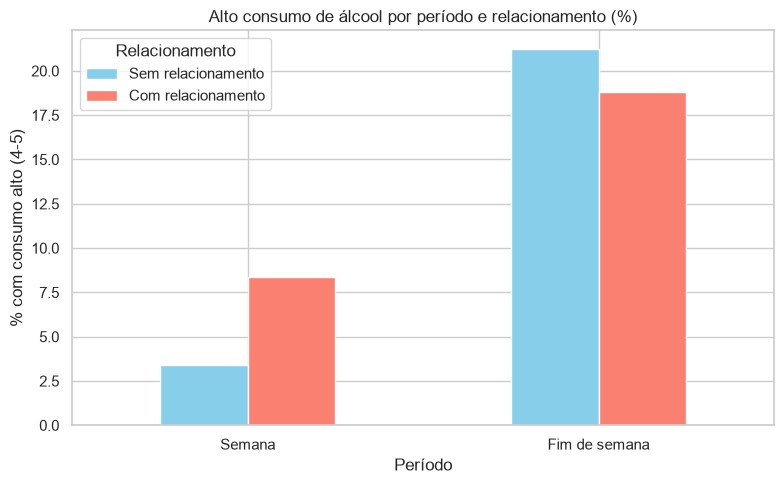

In [3]:
alc_labels = {1:'Muito baixo',2:'Baixo',3:'Médio',4:'Alto',5:'Muito alto'}
df['dalc_label'] = df['Dalc'].map(alc_labels)
df['walc_label'] = df['Walc'].map(alc_labels)

for var, titulo in [('Dalc','consumo de álcool durante a semana'),('Walc','consumo de álcool no fim de semana')]:
    print(f'=== {titulo} ===')
    ct = pd.crosstab(df[var], df['romantic'])[['no','yes']]
    ct.columns = ['Sem relacionamento','Com relacionamento']
    print('Contagem:')
    print(ct)
    ct_pct = pd.crosstab(df[var], df['romantic'], normalize='columns')*100
    ct_pct = ct_pct[['no','yes']]
    ct_pct.columns = ['Sem relacionamento','Com relacionamento']
    print('\nPercentual por grupo:')
    print(ct_pct.round(2))
    chi2, p, dof, exp = stats.chi2_contingency(pd.crosstab(df[var], df['romantic']))
    print(f'\nQui-quadrado: chi2={chi2:.3f}, gl={dof}, p-valor={p:.4f}\n')

    fig, ax = plt.subplots(figsize=(9,5))
    ct_pct.plot(kind='bar', ax=ax, color=['skyblue','salmon'])
    ax.set_title(f'{titulo} por relacionamento amoroso (%)')
    ax.set_xlabel('Nível de consumo (1-5)')
    ax.set_ylabel('Porcentagem de estudantes')
    ax.set_xticklabels([alc_labels[i] for i in sorted(df[var].unique())], rotation=0)
    ax.legend(title='Relacionamento')
    plt.tight_layout()
    plt.show()

df['high_dalc'] = df['Dalc'] >= 4
df['high_walc'] = df['Walc'] >= 4
rate_d_no = df.loc[df['romantic']=='no','high_dalc'].mean()*100
rate_d_yes = df.loc[df['romantic']=='yes','high_dalc'].mean()*100
rate_w_no = df.loc[df['romantic']=='no','high_walc'].mean()*100
rate_w_yes = df.loc[df['romantic']=='yes','high_walc'].mean()*100
diff_d = abs(rate_d_yes - rate_d_no)
diff_w = abs(rate_w_yes - rate_w_no)
print(f'Alto consumo (semana): sem={rate_d_no:.2f}%, com={rate_d_yes:.2f}% (diferença de {diff_d:.2f} pp)')
print(f'Alto consumo (fim de semana): sem={rate_w_no:.2f}%, com={rate_w_yes:.2f}% (diferença de {diff_w:.2f} pp)')

high_tab = pd.DataFrame({'Semana':[rate_d_no, rate_d_yes],'Fim de semana':[rate_w_no, rate_w_yes]}, index=['Sem relacionamento','Com relacionamento']).T
fig, ax = plt.subplots(figsize=(8,5))
high_tab.plot(kind='bar', ax=ax, color=['skyblue','salmon'])
ax.set_title('Alto consumo de álcool por período e relacionamento (%)')
ax.set_xlabel('Período')
ax.set_ylabel('% com consumo alto (4-5)')
ax.set_xticklabels(['Semana','Fim de semana'], rotation=0)
ax.legend(title='Relacionamento')
plt.tight_layout()
plt.show()


**Relatório - Pergunta 2:**

- **Alto consumo (4-5):** semana sem=3.41%, com=8.37%; fim de semana sem=21.22%, com=18.83%.
- Durante a semana, estudantes em relacionamento apresentam maior proporção de consumo alto (8,37% vs 3,41%).
- No fim de semana, não há diferença significativa (18,83% vs 21,22%).
- **Conclusão:** há indícios de maior consumo de álcool durante a semana entre quem tem relacionamento amoroso; no fim de semana o padrão é semelhante.


---
## Pergunta 3
**Como o grau de escolaridade dos pais influencia o desejo de ensino superior?**
---


População total: 649
Limite de 2%: 13.0 estudantes

Tamanho dos grupos - Mãe (Medu):
Medu
0      6
1    143
2    186
3    139
4    175
Name: count, dtype: int64

Tamanho dos grupos - Pai (Fedu):
Fedu
0      7
1    174
2    209
3    131
4    128
Name: count, dtype: int64

Grupos eliminados (mãe): [0]
Grupos eliminados (pai): [0]

Dimensão após filtragem: (637, 38)

Taxa (mãe):
Medu
1    80.43
2    85.48
3    91.37
4    98.85
Name: higher, dtype: float64
Taxa (pai):
Fedu
1    81.40
2    87.38
3    93.89
4    98.44
Name: higher, dtype: float64


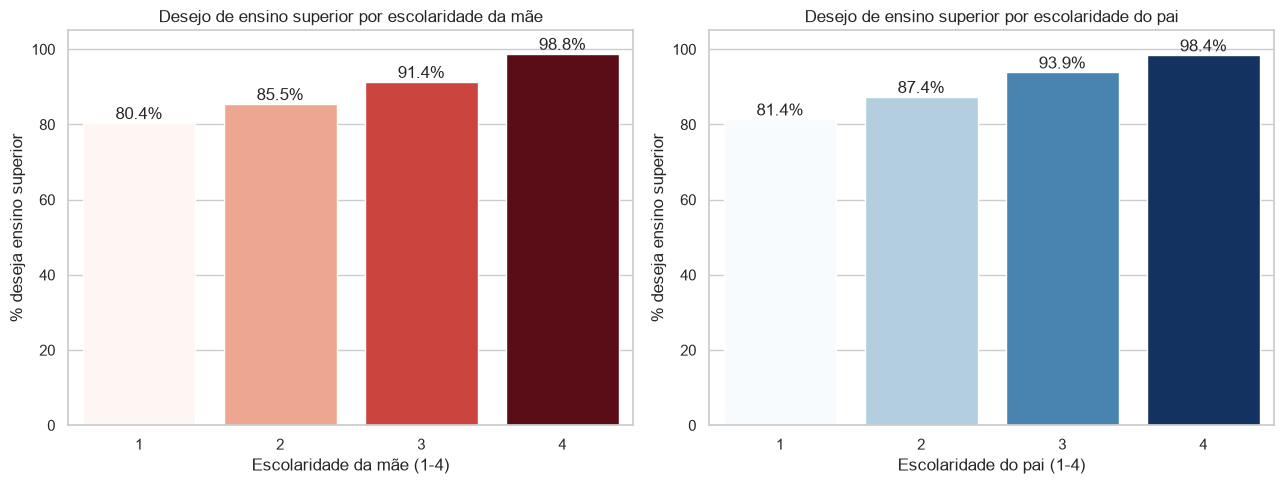

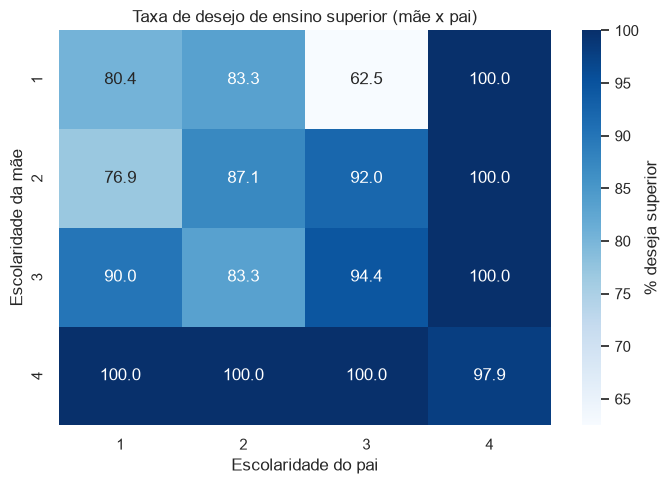

In [4]:
total = len(df)
limite = 0.02 * total
print(f'População total: {total}')
print(f'Limite de 2%: {limite:.1f} estudantes\n')
print('Tamanho dos grupos - Mãe (Medu):')
print(df['Medu'].value_counts().sort_index())
print('\nTamanho dos grupos - Pai (Fedu):')
print(df['Fedu'].value_counts().sort_index())

elim_mae = [g for g in df['Medu'].value_counts().index if df['Medu'].value_counts()[g] < limite]
elim_pai = [g for g in df['Fedu'].value_counts().index if df['Fedu'].value_counts()[g] < limite]
print('\nGrupos eliminados (mãe):', elim_mae)
print('Grupos eliminados (pai):', elim_pai)

df_f = df[~df['Medu'].isin(elim_mae) & ~df['Fedu'].isin(elim_pai)].copy()
print('\nDimensão após filtragem:', df_f.shape)

rate_m = df_f.groupby('Medu')['higher'].apply(lambda s:(s=='yes').mean()*100).round(2)
rate_f = df_f.groupby('Fedu')['higher'].apply(lambda s:(s=='yes').mean()*100).round(2)
print('\nTaxa (mãe):')
print(rate_m)
print('Taxa (pai):')
print(rate_f)

fig, axes = plt.subplots(1, 2, figsize=(13,5))
sns.barplot(x=rate_m.index, y=rate_m.values, hue=rate_m.index, palette='Reds', legend=False, ax=axes[0])
axes[0].set_title('Desejo de ensino superior por escolaridade da mãe')
axes[0].set_xlabel('Escolaridade da mãe (1-4)')
axes[0].set_ylabel('% deseja ensino superior')
axes[0].set_ylim(0,105)
for i,v in enumerate(rate_m.values):
    axes[0].text(i, v+1, f'{v:.1f}%', ha='center')

sns.barplot(x=rate_f.index, y=rate_f.values, hue=rate_f.index, palette='Blues', legend=False, ax=axes[1])
axes[1].set_title('Desejo de ensino superior por escolaridade do pai')
axes[1].set_xlabel('Escolaridade do pai (1-4)')
axes[1].set_ylabel('% deseja ensino superior')
axes[1].set_ylim(0,105)
for i,v in enumerate(rate_f.values):
    axes[1].text(i, v+1, f'{v:.1f}%', ha='center')
plt.tight_layout()
plt.show()

pivot = df_f.pivot_table(index='Medu', columns='Fedu', values='higher', aggfunc=lambda x:(x=='yes').mean()*100)
fig, ax = plt.subplots(figsize=(7,5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='Blues', ax=ax, cbar_kws={'label':'% deseja superior'})
ax.set_title('Taxa de desejo de ensino superior (mãe x pai)')
ax.set_xlabel('Escolaridade do pai')
ax.set_ylabel('Escolaridade da mãe')
plt.tight_layout()
plt.show()


**Relatório - Pergunta 3:**

- População total: 649 estudantes; limite de 2% = 13.0.
- Grupos eliminados: mãe nível 0 (6 estudantes, 0.9%), pai nível 0 (7 estudantes, 1.1%).
- Após filtragem, 637 estudantes (níveis 1-4).
- Mãe: taxa de desejo de superior de 80.4% (primária) a 98.9% (superior).
- Pai: taxa de 81.4% (primária) a 98.4% (superior).
- **Conclusão:** maior escolaridade dos pais (especialmente da mãe) está associada a maior desejo de ensino superior.
